<a href="https://colab.research.google.com/github/kim-guenyoung/LinearAlgebra/blob/main/202221039_%EA%B9%80%EA%B7%BC%EC%98%81.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

##중앙조종석

In [32]:
%%writefile utils.py

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

import utils
def draw_object(ax, LEN):
    p1 = np.array([0,0])
    p2 = np.array([LEN, 0])
    p3 = np.array([LEN, LEN])
    p4 = np.array([0, LEN])

    #중앙 조종석
    draw_cockpit(ax, p1, p2, p3, p4, LEN)
    draw_right_arm(ax, p1, p2, p3, p4, LEN)


def draw_axis(ax, INF):
    ax.axhline(0, color = 'black', alpha=0.3)
    ax.axvline(0, color = 'black', alpha=0.3) #투명도 0.3 축 색깔
    ax.set_xlim(-INF, INF)
    ax.set_ylim(-INF, INF)
    ax.set_aspect('equal') #정사각형 모양으로 백보드 그리기




def translate(p, dx, dy):
  #동차좌표계(homogeneous coordinate)으로 변환
    hp = np.array([p[0], p[1], 1])
    #이동 변환 행렬
    m = np.array([
        [1.0, 0.0, dx],
        [0.0, 1.0, dy],
        [0.0, 0.0, 1.0]
        ])
    #행렬 * 벡터
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def rotate(p, theta):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [np.cos(theta), -np.sin(theta), 0.0],
        [np.sin(theta), np.cos(theta), 0.0],
        [0.0, 0.0, 1.0]
        ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def scale(p, sx, sy):
    hp = np.array([p[0], p[1], 1.0])
    m = np.array([
        [sx, 0.0, 0.0],
        [0.0, sy, 0.0],
        [0.0, 0.0, 1.0]
        ])
    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def shear_x(p, sx):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, sx, 0.0],
        [0.0, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])

def shear_y(p, sy):
    hp = np.array([p[0], p[1], 1.0])

    m = np.array([
        [1.0, 0.0, 0.0],
        [sy, 1.0, 0.0],
        [0.0, 0.0, 1.0]
    ])

    q = np.dot(m, hp)
    return np.array([q[0], q[1]])



def reflect_x(p):
    return np.array([p[0], -p[1]])

def reflect_y(p):
    return np.array([-p[0], p[1]])



def draw_right_arm(ax, p1, p2, p3, p4, LEN):
    pts = [p1, p2, p3, p4]

    # 원점 중심으로 이동
    pts = [translate(p, -LEN/2, -LEN/2) for p in pts]
    pts = [scale(p, 1.3, 4) for p in pts]

    #shear해서 평행사변형 만들어주기
    pts[2] = shear_y(pts[2], 4)

    # 원점에서 오른쪽 위 날개 만들기(평행이동)
    pts = [translate(p, 780, 200) for p in pts]
    # 오른쪽 날개
    arm1 = pts

    # 오른쪽 아래 날개(오른쪽 위 날개 x축 대칭)
    arm2 = [reflect_x(p) for p in pts]

    # 왼쪽 위 날개(오른쪽 날개와 y축 대칭)
    arm3 = [reflect_y(p) for p in pts]

    # 왼쪽 아래날개(오른쪽 위 날개 x축, y축 대칭)
    arm4 = [reflect_y(reflect_x(p)) for p in pts]

    for arm in [arm1, arm2, arm3, arm4]:
        ax.add_patch(Polygon(arm, facecolor='tab:blue'))



def draw_cockpit(ax, p1, p2, p3, p4, LEN):
    my_polygon = Polygon([p1, p2, p3, p4])

    #원점으로 먼저 이동
    pts = [translate(p, -LEN/2, -LEN/2)
        for p in [p1, p2, p3, p4]]

    #회전이동
    pts = [rotate(p, np.radians(45))
        for p in pts]

    #2.5배 키우기
    pts = [scale(p, 4, 4)
        for p in pts]

    pts2 = [scale(p, 3, 0.5)
        for p in pts]


    pts4 = [scale(p, 1.4, 0.2)
        for p in pts]

    my_polygon1 = Polygon(pts) #가운데 다이아몬드
    my_polygon2 = Polygon(pts2) #찌그러진 다이아몬드 큰 거
    my_polygon2_2 = Polygon(pts4, facecolor = "white")#찌그러진 다이아몬드 작은 거



    #큰 다이아몬드(파랑) + 작은 다이아몬드(하얀색) + 중앙 조종석
    ax.add_patch(my_polygon2) #그려짐
    ax.add_patch(my_polygon2_2) #그려짐
    ax.add_patch(my_polygon1) #그려짐





Overwriting utils.py


In [26]:
%%writefile main.py


import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon

from utils import (
    translate, rotate, scale, draw_axis, draw_object,
    shear_x, shear_y, reflect_x, reflect_y
)



INF = 1000 #그림판 크기
LEN = 100 #처음 사각형 크기

fig, ax = plt.subplots()
draw_axis(ax, INF)
draw_object(ax, LEN)
plt.show()


Overwriting main.py


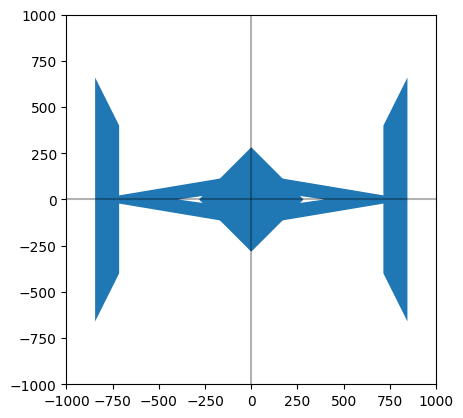

<Figure size 640x480 with 0 Axes>

In [37]:
%run main.py